In [1]:
import os
import torch
os.environ['TORCH'] = torch.__version__
print(torch.__version__)

!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q git+https://github.com/pyg-team/pytorch_geometric.git

2.10.0+cu128
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [26]:
!pip install -qq fvcore torchmetrics simtorch CKA

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATConv
from torch_geometric.datasets import Planetoid
from torch_geometric.data import DataLoader

# Define the GAT model
class GAT(nn.Module):
    def __init__(self, in_features, hidden_size, num_classes, num_heads=1, dropout=0.6):
        super(GAT, self).__init__()
        self.conv1 = GATConv(in_features, hidden_size, heads=num_heads, dropout=dropout)
        self.conv2 = GATConv(hidden_size * num_heads, num_classes, dropout=dropout)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

# Load the Cora dataset
dataset = Planetoid(root='/tmp/Cora', name='Cora')

# Create data loaders for training and testing
train_loader = DataLoader(dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset, batch_size=64)

# Initialize the GAT model
model = GAT(dataset.num_features, hidden_size=64, num_classes=dataset.num_classes, num_heads=8, dropout=0.6)

# Define the loss function and optimizer
criterion = nn.NLLLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

# Training loop
def train():
    model.train()
    for data in train_loader:
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)
        loss = criterion(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()

# Evaluation function
def evaluate(loader):
    model.eval()
    correct = 0
    total = 0
    for data in loader:
        with torch.no_grad():
            out = model(data.x, data.edge_index)
            _, predicted = torch.max(out[data.test_mask], dim=1)
            correct += (predicted == data.y[data.test_mask]).sum().item()
            total += data.test_mask.sum().item()
    return correct / total

# Training loop
for epoch in range(200):
    train()
    train_acc = evaluate(train_loader)
    test_acc = evaluate(test_loader)
    print(f"Epoch: {epoch + 1}, Train Accuracy: {train_acc:.4f}, Test Accuracy: {test_acc:.4f}")

/tmp/ipykernel_24765/3872370318.py:25: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  train_loader = DataLoader(dataset, batch_size=64, shuffle=True)
/tmp/ipykernel_24765/3872370318.py:26: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  test_loader = DataLoader(dataset, batch_size=64)


Epoch: 1, Train Accuracy: 0.5010, Test Accuracy: 0.5010
Epoch: 2, Train Accuracy: 0.7800, Test Accuracy: 0.7800
Epoch: 3, Train Accuracy: 0.7780, Test Accuracy: 0.7780
Epoch: 4, Train Accuracy: 0.7900, Test Accuracy: 0.7900
Epoch: 5, Train Accuracy: 0.7870, Test Accuracy: 0.7870
Epoch: 6, Train Accuracy: 0.7910, Test Accuracy: 0.7910
Epoch: 7, Train Accuracy: 0.7860, Test Accuracy: 0.7860
Epoch: 8, Train Accuracy: 0.7840, Test Accuracy: 0.7840
Epoch: 9, Train Accuracy: 0.7790, Test Accuracy: 0.7790
Epoch: 10, Train Accuracy: 0.7730, Test Accuracy: 0.7730
Epoch: 11, Train Accuracy: 0.7710, Test Accuracy: 0.7710
Epoch: 12, Train Accuracy: 0.7730, Test Accuracy: 0.7730
Epoch: 13, Train Accuracy: 0.7690, Test Accuracy: 0.7690
Epoch: 14, Train Accuracy: 0.7710, Test Accuracy: 0.7710
Epoch: 15, Train Accuracy: 0.7740, Test Accuracy: 0.7740
Epoch: 16, Train Accuracy: 0.7760, Test Accuracy: 0.7760
Epoch: 17, Train Accuracy: 0.7750, Test Accuracy: 0.7750
Epoch: 18, Train Accuracy: 0.7800, Test 

In [3]:
# Import Libraries
from torch_geometric.data import Data
from torch_geometric.nn import GATConv
from torch_geometric.nn import GCNConv
from torch_geometric.datasets import Planetoid
import torch_geometric.transforms as T
from torch.distributions.dirichlet import Dirichlet
import torch.nn.functional as F
import seaborn as sns
import numpy as np
import random
random.seed(42)
import matplotlib.pyplot as plt
name_data = 'Citeseer' # Select dataset here
dataset = Planetoid(root= '/tmp/' + name_data, name = name_data)
dataset.transform = T.NormalizeFeatures()

In [4]:
print(f'Number of graphs: {len(dataset)}')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes: {dataset.num_classes}')
print(50*'=')
data = dataset[0]
print(data)
print(f'Number of nodes: {data.num_nodes}')
print(f'Number of edges: {data.num_edges}')
print(f'Number of training nodes: {data.train_mask.sum()}')
print(f'Training node label rate: {int(data.train_mask.sum()) / data.num_nodes:.2f}')
print(f'Is undirected: {data.is_undirected()}')

Number of graphs: 1
Number of features: 3703
Number of classes: 6
Data(x=[3327, 3703], edge_index=[2, 9104], y=[3327], train_mask=[3327], val_mask=[3327], test_mask=[3327])
Number of nodes: 3327
Number of edges: 9104
Number of training nodes: 120
Training node label rate: 0.04
Is undirected: True


# Training

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATConv

# --- Updated GAT with embeddings extraction ---
class GAT(nn.Module):
    def __init__(self, in_features, hidden_size, num_classes, num_heads=1, dropout=0.6):
        super(GAT, self).__init__()
        self.dropout = dropout
        self.conv1 = GATConv(in_features, hidden_size, heads=num_heads, dropout=dropout)
        self.conv2 = GATConv(hidden_size * num_heads, num_classes, heads=1, concat=False, dropout=dropout)

    def forward(self, x, edge_index, return_embeddings=False):
        """
        Args:
            x: Node features [num_nodes, in_features]
            edge_index: Edge indices
            return_embeddings: If True, returns hidden embeddings from last hidden layer
        """
        x = F.dropout(x, p=self.dropout, training=self.training)
        hidden = F.elu(self.conv1(x, edge_index))  # hidden embeddings
        x = F.dropout(hidden, p=self.dropout, training=self.training)
        out = self.conv2(x, edge_index)            # logits
        if return_embeddings:
            return hidden
        return F.log_softmax(out, dim=1)

    # Convenience method for embeddings
    def get_embeddings(self, x, edge_index):
        self.eval()  # optional: keep model in eval mode for embeddings
        with torch.no_grad():
            return self.forward(x, edge_index, return_embeddings=True)

In [6]:
class GAT1(nn.Module):
    def __init__(self, in_features, hidden_size, num_classes, num_heads=1, dropout=0.6):
        super(GAT1, self).__init__()
        self.conv1 = GATConv(in_features, hidden_size, heads=num_heads, dropout=dropout)
        self.conv2 = GATConv(hidden_size * num_heads, hidden_size, heads=num_heads, dropout=dropout)
        self.conv3 = GATConv(hidden_size * num_heads, num_classes, heads=1, concat=False, dropout=dropout)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = self.conv2(x, edge_index)
        x = F.elu(x)
        x = self.conv3(x, edge_index)
        return F.log_softmax(x, dim=1)

In [20]:
# inspired by
# https://github.com/yuanli2333/CKA-Centered-Kernel-Alignment/blob/master/CKA.py

import math
import torch
import numpy as np

class CKA(object):
    def __init__(self):
        pass

    def centering(self, K):
        n = K.shape[0]
        unit = np.ones([n, n])
        I = np.eye(n)
        H = I - unit / n
        return np.dot(np.dot(H, K), H)

    def rbf(self, X, sigma=None):
        GX = np.dot(X, X.T)
        KX = np.diag(GX) - GX + (np.diag(GX) - GX).T
        if sigma is None:
            mdist = np.median(KX[KX != 0])
            sigma = math.sqrt(mdist)
        KX *= - 0.5 / (sigma * sigma)
        KX = np.exp(KX)
        return KX

    def kernel_HSIC(self, X, Y, sigma):
        return np.sum(self.centering(self.rbf(X, sigma)) * self.centering(self.rbf(Y, sigma)))

    def linear_HSIC(self, X, Y):
        L_X = X @ X.T
        L_Y = Y @ Y.T
        return np.sum(self.centering(L_X) * self.centering(L_Y))

    def linear_CKA(self, X, Y):
        hsic = self.linear_HSIC(X, Y)
        var1 = np.sqrt(self.linear_HSIC(X, X))
        var2 = np.sqrt(self.linear_HSIC(Y, Y))

        return hsic / (var1 * var2)

    def kernel_CKA(self, X, Y, sigma=None):
        hsic = self.kernel_HSIC(X, Y, sigma)
        var1 = np.sqrt(self.kernel_HSIC(X, X, sigma))
        var2 = np.sqrt(self.kernel_HSIC(Y, Y, sigma))

        return hsic / (var1 * var2)


class CudaCKA(object):
    def __init__(self, device):
        self.device = device

    def centering(self, K):
        n = K.shape[0]
        unit = torch.ones([n, n], device=self.device)
        I = torch.eye(n, device=self.device)
        H = I - unit / n
        return torch.matmul(torch.matmul(H, K), H)

    def rbf(self, X, sigma=None):
        GX = torch.matmul(X, X.T)
        KX = torch.diag(GX) - GX + (torch.diag(GX) - GX).T
        if sigma is None:
            mdist = torch.median(KX[KX != 0])
            sigma = math.sqrt(mdist)
        KX *= - 0.5 / (sigma * sigma)
        KX = torch.exp(KX)
        return KX

    def kernel_HSIC(self, X, Y, sigma):
        return torch.sum(self.centering(self.rbf(X, sigma)) * self.centering(self.rbf(Y, sigma)))

    def linear_HSIC(self, X, Y):
        L_X = torch.matmul(X, X.T)
        L_Y = torch.matmul(Y, Y.T)
        return torch.sum(self.centering(L_X) * self.centering(L_Y))

    def linear_CKA(self, X, Y):
        hsic = self.linear_HSIC(X, Y)
        var1 = torch.sqrt(self.linear_HSIC(X, X))
        var2 = torch.sqrt(self.linear_HSIC(Y, Y))

        return hsic / (var1 * var2)

    def kernel_CKA(self, X, Y, sigma=None):
        hsic = self.kernel_HSIC(X, Y, sigma)
        var1 = torch.sqrt(self.kernel_HSIC(X, X, sigma))
        var2 = torch.sqrt(self.kernel_HSIC(Y, Y, sigma))
        return hsic / (var1 * var2)

Epoch 000, Loss: 1.7923
Epoch 100, Loss: 0.6849
Epoch 200, Loss: 0.6659
Epoch 300, Loss: 0.7295
Epoch 400, Loss: 0.6829


Epoch 500, Loss: 0.6603
Total Training Time: 5.17s
Test Accuracy: 0.7292
F1 Score: 0.6959, Precision: 0.6979, Recall: 0.7028
Estimated FLOPs: 4,481,658,880
Expected Calibration Error (ECE): 0.2212
CKA Similarity: 1.0000


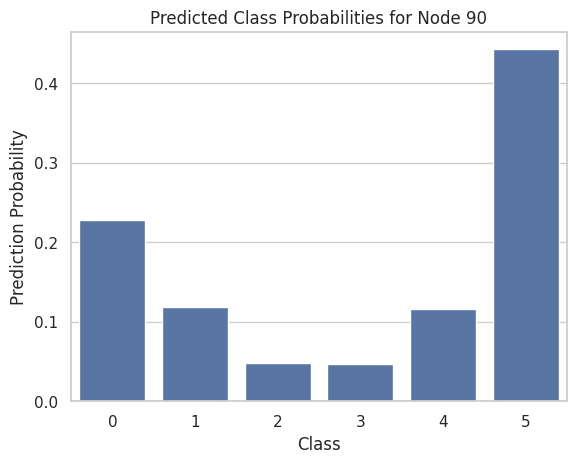

In [21]:
import torch
import torch.nn.functional as F
import time
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import f1_score, precision_score, recall_score
from torchmetrics.classification import CalibrationError
from fvcore.nn import FlopCountAnalysis
import warnings
warnings.filterwarnings("ignore")

# --- Initialize model ---
model = GAT(dataset.num_features, hidden_size=64, num_classes=dataset.num_classes, num_heads=8, dropout=0.5)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)
data = data.to(device)

# --- Optimizer & Loss ---
learning_rate = 0.01
weight_decay = 0.001
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
criterion = torch.nn.CrossEntropyLoss()

# --- Training function ---
def train():
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()

# --- Testing function ---
def test():
    model.eval()
    with torch.no_grad():
        out = model(data.x, data.edge_index)
        pred = out.argmax(dim=1)
        test_mask = data.test_mask
        test_acc = (pred[test_mask] == data.y[test_mask]).sum().item() / test_mask.sum().item()
    return test_acc, pred

# --- Training loop with timing ---
start_time = time.time()
losses = []

for epoch in range(501):
    loss = train()
    losses.append(loss)
    if epoch % 100 == 0:
        print(f'Epoch {epoch:03d}, Loss: {loss:.4f}')

end_time = time.time()
execution_time = end_time - start_time
print(f"Total Training Time: {execution_time:.2f}s")

# --- Evaluate ---
test_acc, pred = test()
print(f"Test Accuracy: {test_acc:.4f}")

# --- Metrics: F1, Precision, Recall ---
y_true = data.y[data.test_mask].cpu().numpy()
y_pred = pred[data.test_mask].cpu().numpy()
f1 = f1_score(y_true, y_pred, average='macro')
precision = precision_score(y_true, y_pred, average='macro')
recall = recall_score(y_true, y_pred, average='macro')
print(f"F1 Score: {f1:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}")

# --- FLOPs calculation ---
flops = FlopCountAnalysis(model, (data.x, data.edge_index))
print(f"Estimated FLOPs: {flops.total():,}")

# --- Calibration Error (ECE) ---
calibration_error = CalibrationError(task="multiclass", num_classes=dataset.num_classes).to(device)
ece = calibration_error(model(data.x, data.edge_index), data.y)
print(f"Expected Calibration Error (ECE): {ece.item():.4f}")

# --- CKA Similarity ---
# You need a second embedding set; here we use the same model as a "teacher" for demonstration  # make sure CudaCKA is imported
with torch.no_grad():
    emb_student = model.get_embeddings(data.x, data.edge_index)
    emb_teacher = model.get_embeddings(data.x, data.edge_index)  # could be a separate pretrained model
    emb_student = emb_student.to(device)
    emb_teacher = emb_teacher.to(device)
    cuda_cka = CudaCKA(device)
    cka_score = cuda_cka.linear_CKA(emb_student, emb_teacher)
print(f"CKA Similarity: {cka_score:.4f}")

# --- Visualization for a sample node ---
sample_idx = 90
sns.set_theme(style="whitegrid")
pred_probs = F.softmax(model(data.x, data.edge_index), dim=-1)[sample_idx].detach().cpu().numpy()
sns.barplot(x=np.arange(dataset.num_classes), y=pred_probs)
plt.xlabel("Class")
plt.ylabel("Prediction Probability")
plt.title(f"Predicted Class Probabilities for Node {sample_idx}")
plt.savefig("class_t.png", dpi=300)
plt.show()

## Training of the distilled student model using DMSD

In [24]:
from torch_geometric.datasets import Planetoid
from torch_geometric.loader import LinkNeighborLoader
name_data = 'Citeseer' # Select dataset here
dataset = Planetoid(root= '/tmp/' + name_data, name = name_data)
dataset.transform = T.NormalizeFeatures()
data = dataset[0]

loader = LinkNeighborLoader(
    data,
    num_neighbors=[100] * 10,
    batch_size=512,
    edge_label_index=data.edge_index,
)
sampled_data = next(iter(loader))

# Divergent Memory

In [25]:
from sklearn.metrics import accuracy_score as acc
from sklearn.metrics import f1_score

Total Training + Evaluation Time: 0.38s
Estimated FLOPs: 4,481,658,880
Test Accuracy: 0.0663
F1 Score: 0.0207, Precision: 0.0110, Recall: 0.1667
CKA Similarity: 0.8863
Expected Calibration Error (ECE): 0.1466


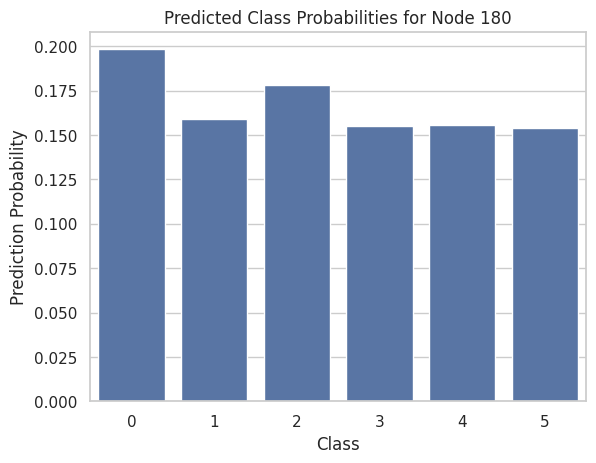

In [27]:
import torch
import torch.nn.functional as F
import os
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import time
from sklearn.metrics import f1_score, precision_score, recall_score
from torchmetrics.classification import CalibrationError
from fvcore.nn import FlopCountAnalysis
import warnings
warnings.filterwarnings("ignore")
# --- Monte Carlo Dropout Uncertainty ---
def mc_dropout_uncertainty(model, x, edge_index, T=10):
    model.train()  # keep dropout active
    preds = []
    for t in range(T):
        logits = model(x, edge_index)
        probs = F.softmax(logits, dim=-1)
        preds.append(probs.unsqueeze(0))
    preds = torch.cat(preds, dim=0)       # [T, N, C]
    variance = preds.var(dim=0)           # [N, C]
    uncertainty = variance.mean(dim=1)    # [N]
    uncertainty = uncertainty / uncertainty.max()  # normalize to [0,1]
    return uncertainty

# --- Initialize Models ---
s_model = GAT(dataset.num_features, hidden_size=64, num_classes=dataset.num_classes, num_heads=8, dropout=0.5)
m_model = GAT(dataset.num_features, hidden_size=64, num_classes=dataset.num_classes, num_heads=8, dropout=0.5)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)
s_model = s_model.to(device)
m_model = m_model.to(device)
data = sampled_data.to(device)

# --- Optimizer & Losses ---
learning_rate = 0.01
decay = 7e-4
s_optimizer = torch.optim.Adam(s_model.parameters(), lr=learning_rate, weight_decay=decay)
criterion_ce = torch.nn.NLLLoss()
criterion_kd = torch.nn.MSELoss()

alpha, beta, gamma = 1.0, 0.005, 0.55
temperature = 10
best_acc = 0
losses_1 = []

# --- Timing ---
start_time = time.time()

# --- KD Training Loop with Monte Carlo Dropout ---
for epoch in range(0, 2):
    model.eval()
    model.load_state_dict(torch.load('memory.pth'))  # load teacher weights
    s_model.train()
    s_optimizer.zero_grad()

    student_logits = s_model(data.x, data.edge_index)

    with torch.no_grad():
        teacher_logits = model(data.x, data.edge_index)

    instance_weight = mc_dropout_uncertainty(s_model, data.x, data.edge_index, T=10)

    student_probs = F.softmax(student_logits / temperature, dim=-1)
    teacher_probs = F.softmax(teacher_logits / temperature, dim=-1)

    if os.path.exists('memory_div.pth'):
        m_model.eval()
        m_model.load_state_dict(torch.load('memory_div.pth'))
        student_logits_mem = m_model(data.x, data.edge_index)
        student_probs_mem = F.softmax(student_logits_mem / temperature, dim=-1)
    else:
        student_probs_mem = student_probs

    batch_loss1 = F.kl_div(student_probs, teacher_probs, reduction="none").sum(-1) / (temperature ** 2)
    batch_loss2 = F.kl_div(student_probs_mem, teacher_probs, reduction="none").sum(-1) / (temperature ** 2)
    loss_kd = torch.mean(batch_loss1 * instance_weight) + torch.mean(batch_loss2 * instance_weight)

    loss_sim = criterion_kd(F.softmax(teacher_logits[data.train_mask] / temperature, dim=-1),
                            F.softmax(student_logits[data.train_mask] / temperature, dim=-1))
    loss_ce = criterion_ce(student_logits[data.train_mask], data.y[data.train_mask])
    loss_div = F.kl_div(student_probs_mem, student_probs, reduction="none").sum(-1) / (temperature ** 2)

    loss = alpha * loss_ce + beta * loss_sim + gamma * loss_kd
    loss.backward()
    s_optimizer.step()
    losses_1.append(loss.item())

    if epoch > 0 and loss_div[epoch-1] < loss_div[epoch]:
        torch.save(s_model.state_dict(), 'memory_div.pth')

    s_model.eval()
    pred = s_model(data.x, data.edge_index).argmax(dim=1)
    test_correct = pred[data.test_mask] == data.y[data.test_mask]
    test_acc = int(test_correct.sum()) / int(data.test_mask.sum())
    if test_acc > best_acc:
        best_acc = test_acc
        torch.save(s_model.state_dict(), 's_div.pth')

# --- End Timing ---
end_time = time.time()
execution_time = end_time - start_time
print(f"Total Training + Evaluation Time: {execution_time:.2f}s")

# --- FLOPs Calculation ---
flops = FlopCountAnalysis(s_model, (data.x, data.edge_index))
print(f"Estimated FLOPs: {flops.total():,}")
# --- Accuracy ---
logits = s_model(data.x, data.edge_index)        # [num_nodes, num_classes]
pred_classes = logits.argmax(dim=1)             # predicted labels
labels = data.y                                 # true labels

test_mask = data.test_mask
accu = (pred_classes[test_mask] == labels[test_mask]).sum().item() / test_mask.sum().item()
print(f"Test Accuracy: {accu:.4f}")
# --- Metrics ---
from sklearn.metrics import f1_score, precision_score, recall_score

pred_classes = s_model(data.x, data.edge_index).argmax(dim=1)
y_true = data.y[data.test_mask].cpu().numpy()
y_pred = pred_classes[data.test_mask].cpu().numpy()

f1 = f1_score(y_true, y_pred, average='macro')
precision = precision_score(y_true, y_pred, average='macro')
recall = recall_score(y_true, y_pred, average='macro')
print(f"F1 Score: {f1:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}")


device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

with torch.no_grad():
    # Get embeddings
    emb_student = s_model.get_embeddings(data.x, data.edge_index)  # [num_nodes, hidden_size*num_heads]
    emb_teacher = model.get_embeddings(data.x, data.edge_index)    # teacher embeddings

    # Move to device
    emb_student = emb_student.to(device)
    emb_teacher = emb_teacher.to(device)

    # Compute CKA similarity on GPU
    cuda_cka = CudaCKA(device)
    cka_score = cuda_cka.linear_CKA(emb_student, emb_teacher)

print(f"CKA Similarity: {cka_score:.4f}")

# --- Expected Calibration Error ---
calibration_error = CalibrationError(task="multiclass",num_classes=6).to(device)
ece = calibration_error(s_model(data.x, data.edge_index), data.y)
print(f"Expected Calibration Error (ECE): {ece.item():.4f}")

# --- Visualization for a sample node with MC Dropout ---
sample_idx = 180
y_vals = F.softmax(s_model(data.x, data.edge_index), dim=-1)[sample_idx].detach().cpu().numpy()
x_vals = np.arange(dataset.num_classes)

sns.set_theme(style="whitegrid")
sns.barplot(x=x_vals, y=y_vals)
plt.xlabel("Class")
plt.ylabel("Prediction Probability")
plt.title(f"Predicted Class Probabilities for Node {sample_idx}")
plt.savefig("class_nsb_mc_dropout_metrics.png", dpi=300)
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATConv
from torch_geometric.datasets import Planetoid
from torch_geometric.data import DataLoader

# Define the GAT model
class GAT(nn.Module):
    def __init__(self, in_features, hidden_size, num_classes, num_heads=1, dropout=0.6):
        super(GAT, self).__init__()
        self.conv1 = GATConv(in_features, hidden_size, heads=num_heads, dropout=dropout)
        self.conv2 = GATConv(hidden_size * num_heads, num_classes, dropout=dropout)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)
criterion = torch.nn.NLLLoss()
# Load the Cora dataset
dataset = Planetoid(root='/tmp/Cora', name='Cora')

# Create data loaders for training and testing
train_loader = DataLoader(dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset, batch_size=64)

# Initialize the Teacher and Student GAT models
teacher_model = GAT(dataset.num_features, hidden_size=64, num_classes=dataset.num_classes, num_heads=8, dropout=0.6)
teacher_model.load_state_dict(torch.load('memory.pth'))
student_model = GAT(dataset.num_features, hidden_size=64, num_classes=dataset.num_classes, num_heads=8, dropout=0.6)
reward_policy = GAT(dataset.num_features, hidden_size=64, num_classes=1, num_heads=8, dropout=0.6)

# Define the optimizer for student model
student_optimizer = torch.optim.Adam(student_model.parameters(), lr=0.01, weight_decay=5e-4)

# Define the optimizer for reward policy
reward_optimizer = torch.optim.Adam(reward_policy.parameters(), lr=0.001)

# Define the loss function for knowledge distillation
distillation_loss = nn.KLDivLoss()
t1=criterion(student_logits[data.train_mask], data.y[data.train_mask])
t2=criterion(student_logits[data.train_mask], data.y[data.train_mask])
# Define the graph-level reward function using KL divergence
def calculate_graph_reward_kl(teacher_logits, student_logits):
    teacher_probs = F.softmax(teacher_logits, dim=1)
    student_probs = F.softmax(student_logits, dim=1)
    return torch.mean(torch.sum(teacher_probs * (torch.log(teacher_probs) - torch.log(student_probs)), dim=1))

# Define the node-level reward function using KL divergence
def calculate_node_reward_kl(teacher_logits, student_logits):
    teacher_probs = F.softmax(teacher_logits, dim=1)
    student_probs = F.softmax(student_logits, dim=1)
    return torch.mean(torch.sum(teacher_probs * (torch.log(teacher_probs) - torch.log(student_probs)), dim=1))

# Training loop
for epoch in range(200):
    teacher_model.train()
    student_model.train()
    reward_policy.train()

    for data in train_loader:
        # Forward pass through the teacher model
        teacher_logits = teacher_model(data.x, data.edge_index)

        # Forward pass through the student model
        student_logits = student_model(data.x, data.edge_index)

        # Calculate the distillation loss using teacher outputs and student logits
        distillation_loss_value = distillation_loss(F.log_softmax(student_logits, dim=1),
                                                    F.softmax(teacher_logits, dim=1))

        # Calculate the graph-level reward using KL divergence
        graph_reward = calculate_graph_reward_kl(teacher_logits, student_logits)

        # Calculate the node-level reward using KL divergence
        node_reward = calculate_node_reward_kl(teacher_logits, student_logits)

        # Optimize the reward policy
        reward_optimizer.zero_grad()
        graph_reward_loss = -graph_reward  # maximize graph reward
        node_reward_loss = -node_reward  # maximize node reward
        reward_loss =  graph_reward_loss + node_reward_loss+t1+t2
        reward_loss.backward(retain_graph=True)
        reward_optimizer.step()

        # Calculate the policy gradient loss
        policy_gradient_loss = -distillation_loss_value * node_reward+t1+t2

        # Optimize the student model using policy gradient
        student_optimizer.zero_grad()
        policy_gradient_loss.backward(retain_graph=True)
        student_optimizer.step()

    # Evaluation
    teacher_model.eval()
    student_model.eval()

    with torch.no_grad():
        # Evaluate the teacher model
        teacher_correct = 0
        teacher_total = 0
        for data in test_loader:
            teacher_outputs = teacher_model(data.x, data.edge_index)
            _, teacher_predicted = torch.max(teacher_outputs, dim=1)
            teacher_correct += (teacher_predicted == data.y).sum().item()
            teacher_total += data.y.size(0)
        teacher_accuracy = teacher_correct / teacher_total

        # Evaluate the student model
        student_correct = 0
        student_total = 0
        for data in test_loader:
            student_outputs = student_model(data.x, data.edge_index)
            _, student_predicted = torch.max(student_outputs, dim=1)
            student_correct += (student_predicted == data.y).sum().item()
            student_total += data.y.size(0)
        student_accuracy = student_correct / student_total

    print(f"Epoch {epoch+1}: Teacher Accuracy: {teacher_accuracy:.4f}, Student Accuracy: {student_accuracy:.4f}")


In [ ]:
import random
from sklearn.metrics import f1_score

# Initialize the model
s_model = GCN(hidden_channels=256)
# Use GPU
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)
s_model = s_model.to(device)
data = sampled_data.to(device)
m_model = GCN(hidden_channels=256)
m_model = m_model.to(device)
# Set the hyperparameters
learning_rate = 0.1
decay = 5e-4
s_optimizer = torch.optim.Adam(s_model.parameters(), lr=learning_rate, weight_decay=decay)
criterion = torch.nn.CrossEntropyLoss()
criterion_kd = torch.nn.MSELoss()
best_acc = 0
best_accs = 0
best_f1=0
losses_1 = []
alpha = 1.0
beta = 0.05
gamma = 0.5
temperature = 100
loss_5 = []

for epoch in range(0, 501):
    model.eval()
    s_model.train()
    s_optimizer.zero_grad()
    student_logits = s_model(data.x, data.edge_index)

    with torch.no_grad():
        teacher_logits = model(data.x, data.edge_index)
        student_probs = F.softmax(student_logits, dim=-1)
        student_entropy = -torch.sum(student_probs * torch.log(student_probs + 1e-6), dim=1)
        instance_weight = student_entropy / torch.log(torch.ones_like(student_entropy) * student_logits.size(1))

    input = F.softmax(student_logits / temperature, dim=-1)
    target = F.softmax(teacher_logits / temperature, dim=-1)

    if os.path.exists('memory_div.pth'):
        m_model.eval()
        m_model.load_state_dict(torch.load('memory_div.pth'))
        student_logits_o = m_model(data.x, data.edge_index)
        input_o = F.softmax(student_logits_o, dim=-1)
    else:
        input_o = input

    batch_loss1 = F.kl_div(input, target, reduction="none").sum(-1) * 1 / (temperature ** 2)
    batch_loss2 = F.kl_div(input_o, target, reduction="none").sum(-1) * 1 / (temperature ** 2)
    loss_kd = torch.mean(batch_loss1 * instance_weight) + torch.mean(batch_loss2 * instance_weight)

    loss_sim = criterion_kd(F.softmax(teacher_logits[data.train_mask] / temperature, dim=-1),
                            F.softmax(student_logits[data.train_mask] / temperature, dim=-1))
    loss_ce = criterion(student_logits[data.train_mask], data.y[data.train_mask])
    loss_div = F.kl_div(input_o, input, reduction="none").sum(-1) * 1 / (temperature ** 2)

    loss = alpha * loss_ce + beta * loss_sim + gamma * loss_kd
    loss.backward()
    s_optimizer.step()
    losses_1.append(loss)

    # if loss_div[epoch-1]<loss_div[epoch]:#epoch*random.randint(0, 1)==0:#
    torch.save(s_model.state_dict(), 'memory_div.pth')

    if epoch % 1 == 0:
        s_model.eval()
        out = s_model(data.x, data.edge_index)
        pred = out.argmax(dim=1)
        preds = s_model(data.x, data.edge_index)
        test_correct = pred[data.test_mask] == data.y[data.test_mask]
        test_acc = int(test_correct.sum()) / int(data.test_mask.sum())
        accu = acc(data.y[data.test_mask].cpu(), pred[data.test_mask].cpu())
        y_true = data.y[data.test_mask].cpu().numpy()
        y_pred = pred[data.test_mask].cpu().numpy()  # Remove max[1].detach()
        f1 = f1_score(y_true, y_pred, average='micro')
        if accu > best_accs:
            best_accs = accu
        if f1 > best_f1:
            best_f1 = f1
        if test_acc > best_acc:
            best_acc = test_acc
            torch.save(s_model.state_dict(), 's_div.pth')

s_model.load_state_dict(torch.load('s_div.pth'))
s_model.eval()
print(f'Best Accuracy: {best_acc:.4f}')
print(f'F1-score: {best_f1:.4f}')
print(f'Sklearn Accuracy: {best_accs:.4f}')
sample = 180
sns.set_theme(style="whitegrid")
print(s_model(data.x, data.edge_index).shape)
pred = s_model(data.x, data.edge_index)
sns.barplot(x=np.array(range(7)), y=(pred[sample].detach().cpu().numpy()))
plt.savefig("class_nsb.png", dpi=300)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch_geometric.data import DataLoader
from torch_geometric.utils import to_networkx
import networkx as nx
import numpy as np
import scipy.io as sio

from torch_geometric.nn import GCNConv


# Define the GCN model
class GCN(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes):
        super(GCN, self).__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)
        x = F.relu(x)
        x = self.fc(x)
        return F.log_softmax(x, dim=1)


# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load the Chameleon dataset
data = sio.loadmat('path/to/chameleon.mat')

# Get adjacency matrix and node labels
adjacency_matrix = data['W']
labels = data['gnd']

# Convert adjacency matrix to NetworkX graph
graph = nx.from_numpy_matrix(adjacency_matrix)

# Get node features and labels
x = torch.tensor(np.eye(adjacency_matrix.shape[0]), dtype=torch.float)  # Use identity matrix as node features
y = torch.tensor(labels.ravel(), dtype=torch.long)

# Convert NetworkX graph to edge_index format
edge_index = torch.tensor([[e[0], e[1]] for e in graph.edges()], dtype=torch.long).t().contiguous()

# Split dataset into train and test
train_mask = torch.zeros_like(y, dtype=torch.bool)
train_mask[:400] = True
test_mask = ~train_mask

# Define model hyperparameters
input_dim = adjacency_matrix.shape[0]
hidden_dim = 64
num_classes = int(y.max()) + 1

# Create model and move it to the device
model = GCN(input_dim, hidden_dim, num_classes).to(device)

# Define loss and optimizer
criterion = nn.NLLLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training loop
def train():
    model.train()
    optimizer.zero_grad()
    output = model(x.to(device), edge_index.to(device))
    loss = criterion(output[train_mask], y[train_mask].to(device))
    loss.backward()
    optimizer.step()

# Testing loop
def test():
    model.eval()
    output = model(x.to(device), edge_index.to(device))
    pred = output.argmax(dim=1)
    correct = pred[test_mask].eq(y[test_mask].to(device)).sum().item()
    acc = correct / test_mask.sum().item()
    return acc

# Train and test the model
for epoch in range(1, 201):
    train()
    test_acc = test()
    print(f'Epoch: {epoch}, Test Accuracy: {test_acc:.4f}')


# Distribution Plot

In [ ]:
def DistributionPlot(RedFunction, BlueFunction, GreenFunction,YellowFunction, RedName, BlueName, GreenName,YellowName,name):
    width = 12
    height = 10
    plt.figure(figsize=(width, height))
    ax1 = sns.kdeplot(RedFunction, color="maroon", label=RedName, linewidth=3)
    ax2 = sns.kdeplot(GreenFunction, color="darkgreen", label=GreenName, ax=ax1, linewidth=3)
    ax3 = sns.kdeplot(BlueFunction, color="indigo", label=BlueName, ax=ax2, linewidth=3)
    ax4 = sns.kdeplot(YellowFunction, color="darkorange", label=YellowName, ax=ax3, linewidth=3)

    #plt.title(Title)
    plt.legend(fontsize=20, loc="upper right", ncol=1)
    plt.xlabel('Node Classes', fontsize=25)
    plt.ylabel('Proportion of Classes', fontsize=25)
    plt.savefig(name+".pdf",dpi=450)
    plt.show()
    plt.close()

In [ ]:
s_model.load_state_dict(torch.load('memory.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_t = out.argmax(dim=1)
s_model.load_state_dict(torch.load('memory_div.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_m = out.argmax(dim=1)
s_model.load_state_dict(torch.load('s_div.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_s = out.argmax(dim=1)
#Title='Distribution  Plot of  Predicted Value Using Test Data vs Data Distribution of Test Data'
name="divergentdg"
DistributionPlot(data.y[data.test_mask].detach().cpu(),pred_t[data.test_mask].detach().cpu(),pred_m[data.test_mask].detach().cpu(),pred_s[data.test_mask].detach().cpu(),"Actual Values (Test)","Prediction (Teacher)","Prediction (Memory)","Prediction (Student)",name)

# Convergent Memory

In [ ]:
import random
# Initialize the model
s_model = GCN(hidden_channels=64)#GNN(64), choose the same as teacher
# Use GPU
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device) # Pretrained teacher model, which is trained above
s_model = s_model.to(device)
data = sampled_data.to(device)
m_model=GCN(hidden_channels=64)
m_model = m_model.to(device)
# Set the hyperparameters
learning_rate = 0.1
decay = 5e-4
s_optimizer = torch.optim.Adam(s_model.parameters(),
                             lr=learning_rate,
                             weight_decay=decay)
criterion = torch.nn.CrossEntropyLoss()
criterion_kd = torch.nn.MSELoss()
best_acc =0
losses_1 = []
alpha = 0.5
beta = 0.250
gamma = 0.25
temperature = 100
loss_5=[]
for epoch in range(0,501):
      model.eval()
      s_model.train()
      s_optimizer.zero_grad()
      student_logits = s_model(data.x, data.edge_index)
      with torch.no_grad():
        teacher_logits = model(data.x, data.edge_index)
        student_probs = F.softmax(student_logits, dim=-1)
        student_entropy = - torch.sum(student_probs * torch.log(student_probs + 1e-6), dim=1)
        instance_weight = student_entropy / torch.log(torch.ones_like(student_entropy) * student_logits.size(1))

      input = F.softmax(student_logits / temperature, dim=-1)
      target = F.softmax(teacher_logits / temperature, dim=-1)
      if os.path.exists('memory_con.pth'):
        m_model.eval()
        m_model.load_state_dict(torch.load('memory_con.pth'))
        student_logits_o = m_model(data.x, data.edge_index)
        input_o = F.softmax(student_logits_o, dim=-1)
      else:
        input_o= input
      batch_loss1 = F.kl_div(input, target, reduction="none").sum(-1) * 1/(temperature ** 2)
      batch_loss2 = F.kl_div(input_o, target, reduction="none").sum(-1) *1/( temperature ** 2)
      loss_kd = torch.mean(batch_loss1 * instance_weight)+ torch.mean(batch_loss2* instance_weight)
      loss_sim = criterion_kd(F.softmax(teacher_logits[data.train_mask]/temperature,dim=-1), F.softmax(student_logits[data.train_mask]/temperature,dim=-1))
      loss_ce = criterion(student_logits[data.train_mask], data.y[data.train_mask])
      loss_div =  F.kl_div(input_o, input, reduction="none").sum(-1) * 1/(temperature ** 2)
      #print(loss_div)
      loss = alpha*loss_ce + beta*loss_sim +gamma*loss_kd
      loss.backward()
      s_optimizer.step()
      losses_1.append(loss)
      if loss_div[epoch-1]>loss_div[epoch]:#epoch*random.randint(0, 1)==0:#
        torch.save(s_model.state_dict(), 'memory_con.pth')

      if epoch % 1 == 0:
        s_model.eval()
        out = s_model(data.x, data.edge_index)
        pred = out.argmax(dim=1)
        preds = s_model(data.x, data.edge_index)
        test_correct = pred[data.test_mask] == data.y[data.test_mask]
        test_acc = int(test_correct.sum()) / int(data.test_mask.sum())
        if test_acc>best_acc:
          best_acc=test_acc
          torch.save(s_model.state_dict(), 's_con.pth')

s_model.load_state_dict(torch.load('s_con.pth'))
s_model.eval()
print(f'Best Accuracy: {best_acc:.4f}')
sample = 180
sns.set_theme(style="whitegrid")
print(s_model(data.x, data.edge_index).shape)
pred = s_model(data.x, data.edge_index)
sns.barplot(x=np.array(range(7)), y=(pred[sample].detach().cpu().numpy()))
plt.savefig("class_nsb.png", dpi=300)

In [ ]:
s_model.load_state_dict(torch.load('memory.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_t = out.argmax(dim=1)
s_model.load_state_dict(torch.load('memory_con.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_m = out.argmax(dim=1)
s_model.load_state_dict(torch.load('s_con.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_s = out.argmax(dim=1)
#Title='Distribution  Plot of  Predicted Value Using Test Data vs Data Distribution of Test Data'
name="convergentdg"
DistributionPlot(data.y[data.test_mask].detach().cpu(),pred_t[data.test_mask].detach().cpu(),pred_m[data.test_mask].detach().cpu(),pred_s[data.test_mask].detach().cpu(),"Actual Values (Test)","Prediction (Teacher)","Prediction (Memory)","Prediction (Student)",name)

# 1-SB Memory

In [ ]:
import random
# Initialize the model
s_model = GCN(hidden_channels=64)#GNN(64), choose the same as teacher
# Use GPU
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device) # Pretrained teacher model, which is trained above
s_model = s_model.to(device)
data = sampled_data.to(device)
m_model=GCN(hidden_channels=64)
m_model = m_model.to(device)
# Set the hyperparameters
learning_rate = 0.1
decay = 5e-4
s_optimizer = torch.optim.Adam(s_model.parameters(),
                             lr=learning_rate,
                             weight_decay=decay)
criterion = torch.nn.CrossEntropyLoss()
criterion_kd = torch.nn.MSELoss()
best_acc =0
losses_1 = []
alpha = 0.5
beta = 0.250
gamma = 0.25
temperature = 100
loss_5=[]
for epoch in range(0,501):
      model.eval()
      s_model.train()
      s_optimizer.zero_grad()
      student_logits = s_model(data.x, data.edge_index)
      with torch.no_grad():
        teacher_logits = model(data.x, data.edge_index)
        student_probs = F.softmax(student_logits, dim=-1)
        student_entropy = - torch.sum(student_probs * torch.log(student_probs + 1e-6), dim=1)
        instance_weight = student_entropy / torch.log(torch.ones_like(student_entropy) * student_logits.size(1))

      input = F.softmax(student_logits / temperature, dim=-1)
      target = F.softmax(teacher_logits / temperature, dim=-1)
      if os.path.exists('memory_1.pth'):
        m_model.eval()
        m_model.load_state_dict(torch.load('memory_1.pth'))
        student_logits_o = m_model(data.x, data.edge_index)
        input_o = F.softmax(student_logits_o, dim=-1)
      else:
        input_o= input
      batch_loss1 = F.kl_div(input, target, reduction="none").sum(-1) * 1/(temperature ** 2)
      batch_loss2 = F.kl_div(input_o, target, reduction="none").sum(-1) *1/( temperature ** 2)
      loss_kd = torch.mean(batch_loss1 * instance_weight)+ torch.mean(batch_loss2* instance_weight)
      loss_sim = criterion_kd(F.softmax(teacher_logits[data.train_mask]/temperature,dim=-1), F.softmax(student_logits[data.train_mask]/temperature,dim=-1))
      loss_ce = criterion(student_logits[data.train_mask], data.y[data.train_mask])
      loss_div =  F.kl_div(input_o, input, reduction="none").sum(-1) * 1/(temperature ** 2)
      #print(loss_div)
      loss = alpha*loss_ce + beta*loss_sim +gamma*loss_kd
      loss.backward()
      s_optimizer.step()
      losses_1.append(loss)
      #if loss_div[epoch-1]<loss_div[epoch]:#epoch*random.randint(0, 1)==0:#
      torch.save(s_model.state_dict(), 'memory_1.pth')

      if epoch % 1 == 0:
        s_model.eval()
        out = s_model(data.x, data.edge_index)
        pred = out.argmax(dim=1)
        preds = s_model(data.x, data.edge_index)
        test_correct = pred[data.test_mask] == data.y[data.test_mask]
        test_acc = int(test_correct.sum()) / int(data.test_mask.sum())
        if test_acc>best_acc:
          best_acc=test_acc
          torch.save(s_model.state_dict(), 's_1.pth')

s_model.load_state_dict(torch.load('s_1.pth'))
s_model.eval()
print(f'Best Accuracy: {best_acc:.4f}')
sample = 180
sns.set_theme(style="whitegrid")
print(s_model(data.x, data.edge_index).shape)
pred = s_model(data.x, data.edge_index)
sns.barplot(x=np.array(range(7)), y=(pred[sample].detach().cpu().numpy()))
plt.savefig("class_nsb.png", dpi=300)

In [ ]:
s_model.load_state_dict(torch.load('memory.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_t = out.argmax(dim=1)
s_model.load_state_dict(torch.load('memory_1.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_m = out.argmax(dim=1)
s_model.load_state_dict(torch.load('s_1.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_s = out.argmax(dim=1)
#Title='Distribution  Plot of  Predicted Value Using Test Data vs Data Distribution of Test Data'
name="1sbdg"
DistributionPlot(data.y[data.test_mask].detach().cpu(),pred_t[data.test_mask].detach().cpu(),pred_m[data.test_mask].detach().cpu(),pred_s[data.test_mask].detach().cpu(),"Actual Values (Test)","Prediction (Teacher)","Prediction (Memory)","Prediction (Student)",name)

# Random Memory

In [ ]:
import random
# Initialize the model
s_model = GCN(hidden_channels=64)#GNN(64), choose the same as teacher
# Use GPU
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device) # Pretrained teacher model, which is trained above
s_model = s_model.to(device)
data = sampled_data.to(device)
m_model=GCN(hidden_channels=64)
m_model = m_model.to(device)
# Set the hyperparameters
learning_rate = 0.1
decay = 5e-4
s_optimizer = torch.optim.Adam(s_model.parameters(),
                             lr=learning_rate,
                             weight_decay=decay)
criterion = torch.nn.CrossEntropyLoss()
criterion_kd = torch.nn.MSELoss()
best_acc =0
losses_1 = []
alpha = 0.5
beta = 0.250
gamma = 0.25
temperature = 100
loss_5=[]
for epoch in range(0,501):
      model.eval()
      s_model.train()
      s_optimizer.zero_grad()
      student_logits = s_model(data.x, data.edge_index)
      with torch.no_grad():
        teacher_logits = model(data.x, data.edge_index)
        student_probs = F.softmax(student_logits, dim=-1)
        student_entropy = - torch.sum(student_probs * torch.log(student_probs + 1e-6), dim=1)
        instance_weight = student_entropy / torch.log(torch.ones_like(student_entropy) * student_logits.size(1))

      input = F.softmax(student_logits / temperature, dim=-1)
      target = F.softmax(teacher_logits / temperature, dim=-1)
      if os.path.exists('memory_r.pth'):
        m_model.eval()
        m_model.load_state_dict(torch.load('memory_r.pth'))
        student_logits_o = m_model(data.x, data.edge_index)
        input_o = F.softmax(student_logits_o, dim=-1)
      else:
        input_o= input
      batch_loss1 = F.kl_div(input, target, reduction="none").sum(-1) * 1/(temperature ** 2)
      batch_loss2 = F.kl_div(input_o, target, reduction="none").sum(-1) *1/( temperature ** 2)
      loss_kd = torch.mean(batch_loss1 * instance_weight)+ torch.mean(batch_loss2* instance_weight)
      loss_sim = criterion_kd(F.softmax(teacher_logits[data.train_mask]/temperature,dim=-1), F.softmax(student_logits[data.train_mask]/temperature,dim=-1))
      loss_ce = criterion(student_logits[data.train_mask], data.y[data.train_mask])
      loss_div =  F.kl_div(input_o, input, reduction="none").sum(-1) * 1/(temperature ** 2)
      #print(loss_div)
      loss = alpha*loss_ce + beta*loss_sim +gamma*loss_kd
      loss.backward()
      s_optimizer.step()
      losses_1.append(loss)
      if epoch*random.randint(0, 1)==0:
        torch.save(s_model.state_dict(), 'memory_r.pth')

      if epoch % 1 == 0:
        s_model.eval()
        out = s_model(data.x, data.edge_index)
        pred = out.argmax(dim=1)
        preds = s_model(data.x, data.edge_index)
        test_correct = pred[data.test_mask] == data.y[data.test_mask]
        test_acc = int(test_correct.sum()) / int(data.test_mask.sum())
        if test_acc>best_acc:
          best_acc=test_acc
          torch.save(s_model.state_dict(), 's_r.pth')

s_model.load_state_dict(torch.load('s_r.pth'))
s_model.eval()
print(f'Best Accuracy: {best_acc:.4f}')
sample = 180
sns.set_theme(style="whitegrid")
print(s_model(data.x, data.edge_index).shape)
pred = s_model(data.x, data.edge_index)
sns.barplot(x=np.array(range(7)), y=(pred[sample].detach().cpu().numpy()))
plt.savefig("class_nsb.png", dpi=300)

In [ ]:
s_model.load_state_dict(torch.load('memory.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_t = out.argmax(dim=1)
s_model.load_state_dict(torch.load('memory_r.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_m = out.argmax(dim=1)
s_model.load_state_dict(torch.load('s_r.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_s = out.argmax(dim=1)
#Title='Distribution  Plot of  Predicted Value Using Test Data vs Data Distribution of Test Data'
name="randomdg"
DistributionPlot(data.y[data.test_mask].detach().cpu(),pred_t[data.test_mask].detach().cpu(),pred_m[data.test_mask].detach().cpu(),pred_s[data.test_mask].detach().cpu(),"Actual Values (Test)","Prediction (Teacher)","Prediction (Memory)","Prediction (Student)",name)

In [ ]:
def DistributionPlot(RedFunction, BlueFunction, GreenFunction,YellowFunction, MaroonFunction,IndigoFunction,RedName, BlueName, GreenName,YellowName,MaroonName,IndigoName,name):
    width = 12
    height = 10
    plt.figure(figsize=(width, height))
    ax1 = sns.kdeplot(RedFunction, color="r", label=RedName, linewidth=3)
    ax2 = sns.kdeplot(GreenFunction, color="g", label=GreenName, ax=ax1, linewidth=3)
    ax3 = sns.kdeplot(BlueFunction, color="b", label=BlueName, ax=ax2, linewidth=3)
    ax4 = sns.kdeplot(YellowFunction, color="y", label=YellowName, ax=ax3, linewidth=3)
    ax5 = sns.kdeplot(MaroonFunction, color="maroon", label=MaroonName, ax=ax4, linewidth=3)
    ax6 = sns.kdeplot(IndigoFunction, color="indigo", label=IndigoName, ax=ax5, linewidth=3)

    #plt.title(Title)
    plt.legend(fontsize=18, loc="upper right", ncol=1)
    plt.xlabel('Node Classes', fontsize=25)
    plt.ylabel('Proportion of Classes', fontsize=25)
    plt.savefig(name+".pdf",dpi=450)
    plt.show()
    plt.close()

In [ ]:
s_model.load_state_dict(torch.load('memory.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_t = out.argmax(dim=1)
s_model.load_state_dict(torch.load('s_div.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_d = out.argmax(dim=1)
s_model.load_state_dict(torch.load('s_con.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_c = out.argmax(dim=1)
s_model.load_state_dict(torch.load('s_1.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_1 = out.argmax(dim=1)
s_model.load_state_dict(torch.load('s_r.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_r = out.argmax(dim=1)
name="alldg"
DistributionPlot(data.y[data.test_mask].detach().cpu(),pred_t[data.test_mask].detach().cpu(),pred_d[data.test_mask].detach().cpu(),pred_c[data.test_mask].detach().cpu(),pred_1[data.test_mask].detach().cpu(),pred_r[data.test_mask].detach().cpu(),"Actual Values (Test)","Prediction (Teacher)","Prediction (Divergent)","Prediction (Convergent)","Prediction (1-SB)","Prediction (Random)",name)

## End of the program

In [ ]:
def DistributionPlot(RedFunction, BlueFunction, GreenFunction,YellowFunction, RedName, BlueName, GreenName,YellowName,name):
    width = 12
    height = 10
    plt.figure(figsize=(width, height))
    ax1 = sns.kdeplot(RedFunction, color="maroon", label=RedName, linewidth=3, fill=True)
    ax2 = sns.kdeplot(GreenFunction, color="darkgreen", label=GreenName, ax=ax1, linewidth=3, fill=True)
    ax3 = sns.kdeplot(BlueFunction, color="indigo", label=BlueName, ax=ax2, linewidth=3, fill=True)
    ax4 = sns.kdeplot(YellowFunction, color="darkorange", label=YellowName, ax=ax3, linewidth=3, fill=True)

    #plt.title(Title)
    plt.legend(fontsize=20, loc="upper right", ncol=1)
    plt.xlabel('Node Classes', fontsize=25)
    plt.ylabel('Proportion of Classes', fontsize=25)
    plt.savefig(name+".png",dpi=450)
    plt.show()
    plt.close()

In [ ]:
s_model = GCN(hidden_channels=64)#GNN(64), choose the same as teacher
# Use GPU
#device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
#model = model.to(device) # Pretrained teacher model, which is trained above
#s_model = s_model.to(device)
#data = sampled_data.to(device)
s_model.load_state_dict(torch.load('memory.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_t = out.argmax(dim=1)
s_model.load_state_dict(torch.load('memory_div.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_m = out.argmax(dim=1)
s_model.load_state_dict(torch.load('s_div.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_s = out.argmax(dim=1)
#Title='Distribution  Plot of  Predicted Value Using Test Data vs Data Distribution of Test Data'
name="divergentdg"
DistributionPlot(data.y[data.test_mask].detach().cpu(),pred_t[data.test_mask].detach().cpu(),pred_m[data.test_mask].detach().cpu(),pred_s[data.test_mask].detach().cpu(),"Actual Values (Test)","Prediction (Teacher)","Prediction (Memory)","Prediction (Student)",name)

In [ ]:
def DistributionPlot(RedFunction, RedName, name):
    width = 12
    height = 10
    plt.figure(figsize=(width, height))
    ax1 = sns.kdeplot(RedFunction, color="orange", label=RedName, linewidth=3, fill=True)
    plt.legend(fontsize=20, loc="upper right", ncol=1)
    plt.xlabel('Node Classes', fontsize=25)
    plt.ylabel('Proportion of Classes', fontsize=25)
    plt.savefig(name+".png",dpi=450)
    plt.show()
    plt.close()

In [ ]:
'''
s_model.load_state_dict(torch.load('memory.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_t = out.argmax(dim=1)
'''
s_model = GCN(hidden_channels=64)
s_model.load_state_dict(torch.load('s_div.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_m = out.argmax(dim=1)
'''
s_model.load_state_dict(torch.load('s_div.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred_s = out.argmax(dim=1)
'''
#Title='Distribution  Plot of  Predicted Value Using Test Data vs Data Distribution of Test Data'
name="student"
DistributionPlot(pred_m[data.test_mask].detach().cpu(),"Student's Distribution",name)

In [ ]:
pred[sample]

In [ ]:
s_model.load_state_dict(torch.load('memory.pth'))
s_model.eval()
out = s_model(data.x, data.edge_index)
pred = out.argmax(dim=1)
preds = s_model(data.x, data.edge_index)
test_correct = pred[data.test_mask] == data.y[data.test_mask]
test_acc = int(test_correct.sum()) / int(data.test_mask.sum())

In [ ]:
test_acc

In [ ]:
Title='Distribution  Plot of  Predicted Value Using Test Data vs Data Distribution of Test Data Convergent'
DistributionPlot(data.y[data.test_mask].detach().cpu(),pred[data.test_mask].detach().cpu(),"Actual Values (Test)","Predicted Values (Test)",Title)